# 02 · Data Cleaning & Preparation (Phase 2)

This notebook runs the three Phase 2 scripts in order and inspects their outputs:

| Step | Script | Output |
|---|---|---|
| 2a | `python/02a_build_reference_mappings.py` | `data/reference/franchise_mapping.csv`, `venue_mapping.csv` |
| 2b | `python/02b_clean_data.py` | `data/processed/matches_clean.csv`, `deliveries_clean.csv`, transformation log |
| 2c | `python/02c_validate_cleaned.py` | before/after validation report |

The scripts are the source of truth; this notebook only executes and explains them.
Raw files are hash-verified and never written to.

In [1]:
import sys
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from importlib import import_module

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / 'python'))
import ipl_config as cfg
step_a = import_module('02a_build_reference_mappings')
step_b = import_module('02b_clean_data')
step_c = import_module('02c_validate_cleaned')
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 80)
sns.set_theme(style='whitegrid')
FIG = cfg.REPORTS_DIR / 'validation' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)

## Step 2a · Approved reference mappings

In [2]:
step_a.main()

[ok] franchise_mapping.csv : 19 raw names -> 15 franchises
[ok] venue_mapping.csv     : 58 raw venues -> 36 grounds
mapping_type
unchanged                       31
city/locality suffix removed    21
historical rename                3
punctuation variant              1
sponsorship name                 1
alternate name                   1


In [3]:
fm = pd.read_csv(cfg.FRANCHISE_MAPPING_CSV)
fm[['team_original', 'franchise', 'franchise_short', 'mapping_type', 'decision_status', 'first_year', 'last_year', 'matches']]

,team_original,franchise,franchise_short,mapping_type,decision_status,first_year,last_year,matches
0,Chennai Super Kings,Chennai Super Kings,CSK,unchanged,NO CHANGE,2008,2024,238
1,Deccan Chargers,Deccan Chargers,DC-08,unchanged,NO CHANGE,2008,2012,75
2,Delhi Daredevils,Delhi Capitals,DC,historical rename,APPROVED 2026-11-08,2008,2018,161
3,Delhi Capitals,Delhi Capitals,DC,unchanged,NO CHANGE,2019,2024,91
4,Gujarat Lions,Gujarat Lions,GL,unchanged,NO CHANGE,2016,2017,30
5,Gujarat Titans,Gujarat Titans,GT,unchanged,NO CHANGE,2022,2024,45
6,Kochi Tuskers Kerala,Kochi Tuskers Kerala,KTK,unchanged,NO CHANGE,2011,2011,14
7,Kolkata Knight Riders,Kolkata Knight Riders,KKR,unchanged,NO CHANGE,2008,2024,251
8,Lucknow Super Giants,Lucknow Super Giants,LSG,unchanged,NO CHANGE,2022,2024,44
9,Mumbai Indians,Mumbai Indians,MI,unchanged,NO CHANGE,2008,2024,261


In [4]:
vm = pd.read_csv(cfg.VENUE_MAPPING_CSV)
vm[vm.mapping_type != 'unchanged'][['venue_original', 'venue_standardized', 'mapping_type', 'verification_status', 'city_standardized', 'matches']]

,venue_original,venue_standardized,mapping_type,verification_status,city_standardized,matches
1,"Arun Jaitley Stadium, Delhi",Arun Jaitley Stadium,city/locality suffix removed,VERIFIED,Delhi,16
2,Feroz Shah Kotla,Arun Jaitley Stadium,historical rename,VERIFIED,Delhi,60
4,"Barsapara Cricket Stadium, Guwahati",Barsapara Cricket Stadium,city/locality suffix removed,VERIFIED,Guwahati,3
5,"Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium, Lucknow",Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium,city/locality suffix removed,VERIFIED,Lucknow,14
7,"Brabourne Stadium, Mumbai",Brabourne Stadium,city/locality suffix removed,VERIFIED,Mumbai,17
11,"Dr DY Patil Sports Academy, Mumbai",Dr DY Patil Sports Academy,city/locality suffix removed,VERIFIED,Navi Mumbai,20
13,"Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium, Visakhapatnam",Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium,city/locality suffix removed,VERIFIED,Visakhapatnam,2
16,"Eden Gardens, Kolkata",Eden Gardens,city/locality suffix removed,VERIFIED,Kolkata,16
19,"Himachal Pradesh Cricket Association Stadium, Dharamsala",Himachal Pradesh Cricket Association Stadium,city/locality suffix removed,VERIFIED,Dharamsala,4
24,"M Chinnaswamy Stadium, Bengaluru",M Chinnaswamy Stadium,city/locality suffix removed,VERIFIED,Bengaluru,14


## Step 2b · Clean and engineer features
Key cricket rules applied (see `documentation/transformation_log.md` for full definitions):
- **Legal delivery** = not a wide and not a no-ball.
- **Ball faced** (batter) = every delivery except wides (no-balls *are* faced).
- **Bowler runs conceded** = batter runs + wides + no-balls (byes, leg-byes, penalty excluded).
- **Bowler wicket** = bowled, caught, caught & bowled, lbw, stumped, hit wicket (run outs etc. excluded).
- **Player out** = `is_wicket` excluding *retired hurt*.
- **Super overs** (inning ≥ 3) kept and flagged; **phase** = Powerplay 1-6, Middle 7-15, Death 16-20.

In [5]:
step_b.main()

[ok] raw verified; matches (1095, 20), deliveries (260920, 17)


[ok] matches_clean.csv    (1095, 44)
[ok] deliveries_clean.csv (260920, 48)
 step      table                            column  rows_affected
    1    matches                       season_year           1095
    2    matches                        is_playoff             66
    3    matches                             venue            506
    4    matches                              city             51
    5    matches                              city             93
    6    matches                             team1            319
    7    matches                             team2            288
    8    matches                       toss_winner            284
    9    matches                            winner            281
   10    matches                          win_type           1095
   11    matches                      target_balls           1092
   12 deliveries                       delivery_id         260920
   13 deliveries                     is_super_over            161


In [6]:
mc = pd.read_csv(cfg.CLEAN_MATCHES); dc = pd.read_csv(cfg.CLEAN_DELIVERIES)
print(mc.shape, dc.shape)
mc.head(3)

(1095, 44) (260920, 48)


,match_id,season_year,season_label_original,match_date,match_type,is_playoff,venue,venue_original,city,city_original,is_city_imputed,team1,team1_original,team2,team2_original,toss_winner,toss_winner_original,toss_decision,toss_winner_batted_first,batting_first_team,chasing_team,winner,winner_original,result,result_margin,win_type,result_for,toss_winner_won,is_super_over,is_no_result,is_dls,method,target_runs,target_overs,target_balls,inn1_runs,inn1_wickets,inn1_legal_balls,inn2_runs,inn2_wickets,inn2_legal_balls,player_of_match,umpire1,umpire2
0,335982,2008,2007/08,2008-04-18,League,0,M Chinnaswamy Stadium,M Chinnaswamy Stadium,Bengaluru,Bangalore,0,Royal Challengers Bengaluru,Royal Challengers Bangalore,Kolkata Knight Riders,Kolkata Knight Riders,Royal Challengers Bengaluru,Royal Challengers Bangalore,field,0,Kolkata Knight Riders,Royal Challengers Bengaluru,Kolkata Knight Riders,Kolkata Knight Riders,runs,140.0,runs,batting first,0.0,0,0,0,NaN,223.0,20.0,120.0,222,3,120,82.0,10.0,91.0,BB McCullum,Asad Rauf,RE Koertzen
1,335983,2008,2007/08,2008-04-19,League,0,Punjab Cricket Association IS Bindra Stadium,"Punjab Cricket Association Stadium, Mohali",Chandigarh,Chandigarh,0,Punjab Kings,Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,Chennai Super Kings,Chennai Super Kings,bat,1,Chennai Super Kings,Punjab Kings,Chennai Super Kings,Chennai Super Kings,runs,33.0,runs,batting first,1.0,0,0,0,NaN,241.0,20.0,120.0,240,5,120,207.0,4.0,120.0,MEK Hussey,MR Benson,SL Shastri
2,335984,2008,2007/08,2008-04-19,League,0,Arun Jaitley Stadium,Feroz Shah Kotla,Delhi,Delhi,0,Delhi Capitals,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,Rajasthan Royals,Rajasthan Royals,bat,1,Rajasthan Royals,Delhi Capitals,Delhi Capitals,Delhi Daredevils,wickets,9.0,wickets,chasing,0.0,0,0,0,NaN,130.0,20.0,120.0,129,8,120,132.0,1.0,91.0,MF Maharoof,Aleem Dar,GA Pratapkumar


In [7]:
dc.head(3)

,delivery_id,match_id,season_year,inning,is_super_over,super_over_number,batting_team_original,batting_team,bowling_team_original,bowling_team,over,over_number,ball,is_wide,is_noball,is_bye,is_legbye,is_penalty,is_legal_delivery,legal_ball_in_over,over_legal_balls,is_seven_ball_over,phase,batter,non_striker,bowler,batsman_runs,extra_runs,total_runs,extras_type,wide_runs,noball_runs,bye_runs,legbye_runs,penalty_runs,bowler_runs_conceded,is_ball_faced,is_dot_ball,is_four,is_six,is_wicket,player_dismissed,dismissal_kind,fielder,is_retired_hurt,is_player_out,is_bowler_wicket,is_run_out
0,1,335982,2008,1,0,0,Kolkata Knight Riders,Kolkata Knight Riders,Royal Challengers Bangalore,Royal Challengers Bengaluru,0,1,1,0,0,0,1,0,1,1,6,0,Powerplay,SC Ganguly,BB McCullum,P Kumar,0,1,1,legbyes,0,0,0,1,0,0,1,0,0,0,0,NaN,NaN,NaN,0,0,0,0
1,2,335982,2008,1,0,0,Kolkata Knight Riders,Kolkata Knight Riders,Royal Challengers Bangalore,Royal Challengers Bengaluru,0,1,2,0,0,0,0,0,1,2,6,0,Powerplay,BB McCullum,SC Ganguly,P Kumar,0,0,0,NaN,0,0,0,0,0,0,1,1,0,0,0,NaN,NaN,NaN,0,0,0,0
2,3,335982,2008,1,0,0,Kolkata Knight Riders,Kolkata Knight Riders,Royal Challengers Bangalore,Royal Challengers Bengaluru,0,1,3,1,0,0,0,0,0,2,6,0,Powerplay,BB McCullum,SC Ganguly,P Kumar,0,1,1,wides,1,0,0,0,0,1,0,0,0,0,0,NaN,NaN,NaN,0,0,0,0


In [8]:
pd.read_csv(cfg.VALIDATION_DIR / 'phase2_transformation_log.csv')

,step,table,column,action,rows_affected,detail
0,1,matches,season_year,derive from match date,1095,"178 rows whose label differs from play year ('2007/08','2009/10','2020/21')"
1,2,matches,is_playoff,flag non-League matches,66,NaN
2,3,matches,venue,standardise via venue_mapping.csv,506,58 raw strings -> 36 grounds
3,4,matches,city,fill missing city from same venue's recorded city,51,"{'Dubai': 33, 'Sharjah': 18}"
4,5,matches,city,standardise city spelling per ground (approved),93,"{('Bangalore', 'Bengaluru'): 65, ('Mumbai', 'Navi Mumbai'): 28}"
5,6,matches,team1,standardise franchise via franchise_mapping.csv,319,NaN
6,7,matches,team2,standardise franchise via franchise_mapping.csv,288,NaN
7,8,matches,toss_winner,standardise franchise via franchise_mapping.csv,284,NaN
8,9,matches,winner,standardise franchise via franchise_mapping.csv,281,NaN
9,10,matches,win_type,derive: runs / wickets / super over (tie) / no result,1095,NaN


## Step 2c · Before/after validation

In [9]:
step_c.main()

                          metric     before (raw)  after (clean)
                      Match rows             1095           1095
                   Delivery rows           260920         260920
                 Matches columns               20             44
              Deliveries columns               17             48
             Distinct team names               19             15
                 Distinct venues               58             36
   Distinct cities (non-missing)               36             35
                  Missing cities               51              0
    Season labels / season years               17             17
                Total runs (all)           347756         347756
         Total runs (regulation)           347470         347470
          Legal deliveries (all)           251471         251471
              Raw is_wicket rows            12950          12950
Player outs (excl. retired hurt)              n/a          12935
                  Bowler 

## Visual checks

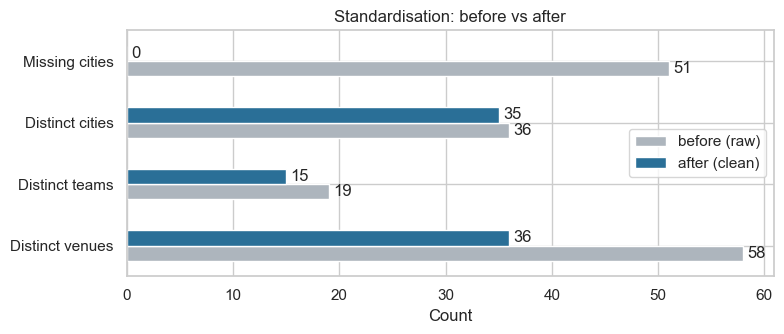

In [10]:
raw_m = pd.read_csv(cfg.RAW_MATCHES)
cmp = pd.DataFrame({
    'before (raw)': [raw_m.venue.nunique(), len(set(raw_m.team1) | set(raw_m.team2)), raw_m.city.nunique(), int(raw_m.city.isna().sum())],
    'after (clean)': [mc.venue.nunique(), len(set(mc.team1) | set(mc.team2)), mc.city.nunique(), int(mc.city.isna().sum())]},
    index=['Distinct venues', 'Distinct teams', 'Distinct cities', 'Missing cities'])
ax = cmp.plot.barh(figsize=(8, 3.5), color=['#adb5bd', '#2a6f97'])
ax.set_title('Standardisation: before vs after'); ax.set_xlabel('Count')
for c in ax.containers: ax.bar_label(c, padding=3)
plt.tight_layout(); plt.savefig(FIG / 'standardisation_before_after.png', dpi=150); plt.show()

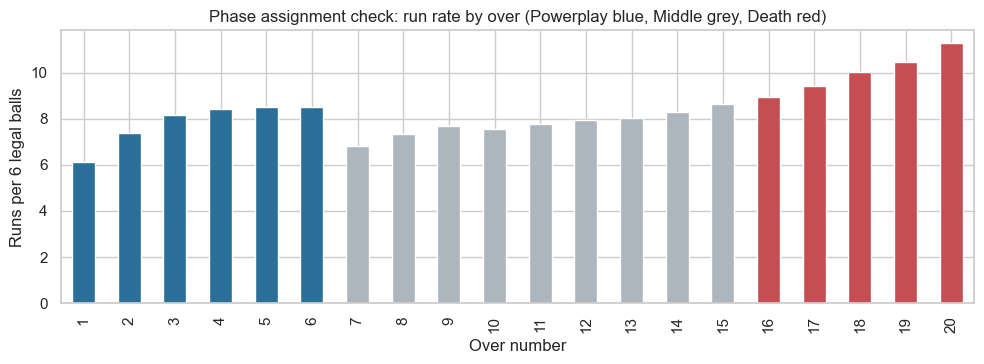

In [11]:
reg = dc[dc.is_super_over == 0]
per_over = reg.groupby('over_number').agg(runs=('total_runs', 'sum'), legal=('is_legal_delivery', 'sum'))
per_over['run_rate'] = per_over.runs / per_over.legal * 6
colors = per_over.index.map(lambda o: '#2a6f97' if o <= 6 else ('#adb5bd' if o <= 15 else '#c44e52'))
ax = per_over.run_rate.plot.bar(figsize=(10, 3.8), color=colors)
ax.set_title('Phase assignment check: run rate by over (Powerplay blue, Middle grey, Death red)')
ax.set_xlabel('Over number'); ax.set_ylabel('Runs per 6 legal balls')
plt.tight_layout(); plt.savefig(FIG / 'run_rate_by_over_phase_check.png', dpi=150); plt.show()

The chart is a **sanity check** that the phase columns are built correctly, not EDA: the expected
T20 shape appears (scoring dips after the powerplay and rises in the death overs).

## Flagged-but-retained records

In [12]:
flags = pd.Series({
    'Super-over deliveries': int(dc.is_super_over.sum()),
    'Retired-hurt rows (not out)': int(dc.is_retired_hurt.sum()),
    'Rows in 7-legal-ball overs': int(dc.is_seven_ball_over.sum()),
    'No-result matches': int(mc.is_no_result.sum()),
    'DLS matches': int(mc.is_dls.sum()),
    'Tied matches (super over)': int(mc.is_super_over.sum()),
    'Imputed cities': int(mc.is_city_imputed.sum())})
flags.to_frame('rows/matches kept & flagged')

,rows/matches kept & flagged
Super-over deliveries,161
Retired-hurt rows (not out),15
Rows in 7-legal-ball overs,225
No-result matches,5
DLS matches,21
Tied matches (super over),14
Imputed cities,51


In [13]:
mc[(mc.is_dls == 1) & (mc.win_type == 'runs') & (mc.result_for == 'chasing')][
    ['match_id', 'season_year', 'chasing_team', 'target_runs', 'target_overs', 'inn2_runs', 'result_margin']]

,match_id,season_year,chasing_team,target_runs,target_overs,inn2_runs,result_margin
38,336022,2008,Punjab Kings,89.0,8.0,94.0,6.0
41,336025,2008,Chennai Super Kings,53.0,8.0,55.0,3.0
63,392186,2009,Kolkata Knight Riders,69.0,9.2,79.0,11.0
221,501245,2011,Kolkata Knight Riders,52.0,10.0,61.0,10.0
538,980943,2016,Rising Pune Supergiants,61.0,11.0,94.0,34.0
565,980997,2016,Rising Pune Supergiants,58.0,11.0,76.0,19.0


**DLS investigation:** these 6 chases were stopped by rain while ahead of the revised par score, so the
chasing team is recorded as winning *by runs* (margin = second-innings runs − par, par = target − 1). This is a
legitimate DLS outcome, verified by check V53b, and kept as recorded.